# XAI : qu'est-ce qui pousse le U-Net à prédire « anomalie » ? (test d'occlusion)

**Question.** Un score élevé ne dit pas *pourquoi* le modèle détecte un obstacle. Regarde-t-il l'obstacle lui-même, ou le décor autour (cônes, lignes de la route, bords) ? C'est la partie XAI suggérée par le professeur.

**Méthode : test d'occlusion.** On masque tour à tour chaque zone de l'image avec un carré gris moyen (64×64 pixels, pas de 32) et on mesure **de combien baisse la confiance du modèle**. Une zone dont le masquage fait chuter la confiance est une zone dont dépend la décision. On obtient une carte de sensibilité : **rouge = zone importante pour la décision**, bleu = zone dont le masquage augmente la confiance.

Deux scores sont suivis en parallèle :
- **score « détection »** : probabilité moyenne sur la région que le modèle prédit comme anomalie (au seuil du BO). Il répond à : *de quoi dépend la détection ?*
- **score « obstacle réel »** : probabilité moyenne sur le masque vérité terrain. Il répond à : *de quoi dépend la confiance sur le vrai obstacle ?*

**Pourquoi cette méthode ?** Elle fonctionne avec n'importe quel modèle sans toucher à son architecture, elle s'explique en une phrase, et elle ne demande aucun entraînement. Son coût est de 120 passages avant par image.

**Modèle analysé :** U-Net ResNet34 pré-entraîné (le modèle retenu pour le BO), au seuil du mode « rappel visé 90 % » du notebook de comparaison. Aucun entraînement dans ce notebook.

In [1]:
import os, re, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from scipy import ndimage
from sklearn.model_selection import train_test_split
from IPython.display import display

# OpenCV ne doit pas lancer ses propres threads (évite les conflits avec PyTorch)
cv2.setNumThreads(0)

print("PyTorch :", torch.__version__, "| smp :", smp.__version__)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Périphérique :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "pas de GPU (l'entraînement sera lent)")

c:\Projects\deep_learning\RoadAnomaly\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch : 2.15.0+cpu | smp : 0.6.0
Périphérique : cpu | pas de GPU (l'entraînement sera lent)


In [2]:
SEED = 42
IMG_W, IMG_H = 512, 288               # même résolution que l'entraînement
PATCH, STRIDE = 64, 32                # taille du carré masqué et pas de déplacement (STRIDE = 64 pour un test 4 fois plus rapide)
CASES = ["animals12_Collared_Peccary_crossing_the_road",   # obstacle très bien détecté
         "obstacles04_cardboard_czech_hedgehog",           # cas intermédiaire
         "vehicle02_Broadmoor_Cones_Skidloader"]           # obstacle presque raté (rappel 0,08)

def find_data_root():
    here = os.path.abspath(os.getcwd())
    for _ in range(6):
        for cand in (here, os.path.join(here, "RoadAnomaly")):
            if os.path.exists(os.path.join(cand, "frames")) and os.path.exists(os.path.join(cand, "frame_list.json")):
                return cand
        here = os.path.dirname(here)
    raise FileNotFoundError(f"Dataset introuvable depuis {os.getcwd()} : ouvrir le notebook depuis le dépôt du projet.")

ROOT = find_data_root()
FRAMES = os.path.join(ROOT, "frames")
OUT_DIR = os.path.join(ROOT, "outputs_xai")
os.makedirs(OUT_DIR, exist_ok=True)
CKPT = os.path.join(ROOT, "outputs_unet_resnet34_pretrained", "unet_resnet34_pretrained_best.pt")
assert os.path.exists(CKPT), f"Poids introuvables : {CKPT}"

# Seuil du mode « rappel visé 90 % » trouvé dans le notebook de comparaison (0,27 par défaut)
THR = 0.27
cmp_json = os.path.join(ROOT, "outputs_comparaison_bo", "comparaison_bo.json")
if os.path.exists(cmp_json):
    for r in json.load(open(cmp_json, encoding="utf-8"))["comparaison"]:
        if r["Modèle"] == "U-Net ResNet34 pré-entraîné" and "90" in r["Mode"]:
            THR = float(r["Seuil"])
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Dataset :", ROOT, "| seuil utilisé :", THR, "| carré masqué :", PATCH, "px, pas :", STRIDE, "px")

Dataset : c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly | seuil utilisé : 0.27 | carré masqué : 64 px, pas : 32 px


## 1. Données et modèle

In [3]:
def get_paths(name):
    """Chemins de l'image et du masque à partir d'un nom de frame (avec ou sans .webp)."""
    base = os.path.splitext(name)[0]
    return base, os.path.join(FRAMES, base + ".webp"), os.path.join(FRAMES, base + ".labels", "labels_semantic.png")

def get_category(name):
    m = re.match(r"^([a-zA-Z_]+?)\d", name)
    return m.group(1) if m else "autre"

def build_split_df():
    """Recalcule le découpage exactement comme dans le notebook d'exploration."""
    with open(os.path.join(ROOT, "frame_list.json")) as f:
        frame_list = json.load(f)
    rows = []
    for name in frame_list:
        base, _, mask_p = get_paths(name)
        mask = np.array(Image.open(mask_p))
        rows.append({"name": base, "prop_anomalie": float((mask == 2).mean())})
    d = pd.DataFrame(rows)
    d["categorie"] = d["name"].apply(get_category)
    grandes = ["animals", "obstacles", "cones"]
    d["groupe"] = d["categorie"].apply(lambda c: c if c in grandes else "autres")
    seuil = d["prop_anomalie"].median()
    d["taille"] = np.where(d["prop_anomalie"] < seuil, "petite", "grande")
    d["strat"] = d["groupe"] + "_" + d["taille"]
    trainval, test = train_test_split(d, test_size=0.20, stratify=d["strat"], random_state=SEED)
    train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["strat"], random_state=SEED)
    d["split"] = "train"
    d.loc[val.index, "split"] = "val"
    d.loc[test.index, "split"] = "test"
    return d

SPLIT_CSV = os.path.join(ROOT, "split.csv")
df_new = build_split_df()
if os.path.exists(SPLIT_CSV):
    df = pd.read_csv(SPLIT_CSV)
    same = dict(zip(df["name"], df["split"])) == dict(zip(df_new["name"], df_new["split"]))
    print("split.csv lu. Identique au découpage recalculé :", same)
else:
    df = df_new
    df[["name", "categorie", "groupe", "taille", "prop_anomalie", "split"]].to_csv(SPLIT_CSV, index=False)
    print("split.csv absent : découpage recalculé et sauvegardé.")

train_names = df[df["split"] == "train"]["name"].tolist()
val_names   = df[df["split"] == "val"]["name"].tolist()
test_names  = df[df["split"] == "test"]["name"].tolist()
all_names = train_names + val_names + test_names

# Pas de fuite de données : aucune image dans deux ensembles à la fois
assert not (set(train_names) & set(val_names)) and not (set(train_names) & set(test_names)) and not (set(val_names) & set(test_names))
assert len(set(all_names)) == len(df) == 60
print(f"train = {len(train_names)} | val = {len(val_names)} | test = {len(test_names)}")
print(pd.crosstab(df["split"], df["groupe"]))

split.csv lu. Identique au découpage recalculé : True
train = 36 | val = 12 | test = 12
groupe  animals  autres  cones  obstacles
split                                    
test          6       1      2          3
train        19       3      5          9
val           6       2      1          3


In [4]:
# Chargement en mémoire des 60 paires (image RGB, masque binaire 0/1) : ~220 Mo, entraînement bien plus rapide
def load_raw(name):
    _, img_p, mask_p = get_paths(name)
    img = np.array(Image.open(img_p).convert("RGB"))
    mask = (np.array(Image.open(mask_p)) == 2).astype(np.uint8)   # 2 (anomalie) -> 1, 0 (fond) -> 0
    assert img.shape[:2] == mask.shape, f"Image et masque de tailles différentes : {name}"
    return img, mask

CACHE = {n: load_raw(n) for n in all_names}
H_FULL, W_FULL = next(iter(CACHE.values()))[1].shape
print("Paires chargées :", len(CACHE), "| résolution d'origine :", (W_FULL, H_FULL))

Paires chargées : 60 | résolution d'origine : (1280, 720)


In [5]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
def to_tensor(img_uint8):
    x = (img_uint8.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

ck = torch.load(CKPT, map_location=DEVICE, weights_only=False)
model = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=1)
model.load_state_dict(ck["state_dict"]); model = model.to(DEVICE).eval()
missing = [n for n in CASES if n not in test_names]
print("Modèle chargé. Images d'étude absentes du test :", missing if missing else "aucune")

Modèle chargé. Images d'étude absentes du test : aucune


## 2. Le test d'occlusion
Dans l'espace normalisé, la valeur 0 correspond à la couleur moyenne ImageNet : c'est le « gris moyen » qui remplace la zone masquée.

In [6]:
@torch.no_grad()
def occlusion(name, thr=THR, patch=PATCH, stride=STRIDE, bs=16):
    """Cartes de sensibilité pour une image : baisse de confiance quand chaque zone est masquée."""
    img = cv2.resize(CACHE[name][0], (IMG_W, IMG_H), interpolation=cv2.INTER_AREA)
    gt = cv2.resize(CACHE[name][1], (IMG_W, IMG_H), interpolation=cv2.INTER_NEAREST).astype(bool)
    x0 = to_tensor(img).unsqueeze(0).to(DEVICE)
    p0 = torch.sigmoid(model(x0))[0, 0].cpu().numpy()
    pred0 = p0 >= thr                                           # région détectée par le modèle sans masquage

    def scores(p):                                              # p : (B, H, W)
        s_pred = (p * pred0).sum(axis=(1, 2)) / max(int(pred0.sum()), 1)
        s_gt = (p * gt).sum(axis=(1, 2)) / max(int(gt.sum()), 1)
        return s_pred, s_gt
    base_pred, base_gt = scores(p0[None])

    boxes = [(y, x) for y in range(0, IMG_H - patch + 1, stride) for x in range(0, IMG_W - patch + 1, stride)]
    d_pred, d_gt, cover = (np.zeros((IMG_H, IMG_W), np.float64) for _ in range(3))
    for i in range(0, len(boxes), bs):
        chunk = boxes[i:i + bs]
        xb = x0.repeat(len(chunk), 1, 1, 1).clone()
        for k, (y, x) in enumerate(chunk): xb[k, :, y:y + patch, x:x + patch] = 0.0
        sp, sg = scores(torch.sigmoid(model(xb))[:, 0].cpu().numpy())
        for k, (y, x) in enumerate(chunk):
            d_pred[y:y + patch, x:x + patch] += base_pred[0] - sp[k]
            d_gt[y:y + patch, x:x + patch]   += base_gt[0] - sg[k]
            cover[y:y + patch, x:x + patch]  += 1
    cover = np.maximum(cover, 1)
    return {"img": img, "gt": gt, "p0": p0, "pred0": pred0, "sens_pred": d_pred / cover, "sens_gt": d_gt / cover,
            "base_pred": float(base_pred[0]), "base_gt": float(base_gt[0])}

t0 = time.time()
RES = {}
for n in test_names:
    RES[n] = occlusion(n)
    print(f"{n:50s} | {time.time() - t0:5.0f} s écoulées")

animals12_Collared_Peccary_crossing_the_road       |    22 s écoulées
animals13_jeune_bovin_sur_la_route                 |    44 s écoulées
animals14_Dekemhare_Road                           |    63 s écoulées
animals19_Porte_de_Roubaix                         |    80 s écoulées
animals26_Unnamed_Road_Kazakhstan                  |    98 s écoulées
animals30                                          |   116 s écoulées
cones04_Federation                                 |   134 s écoulées
cones07                                            |   152 s écoulées
obstacles04_cardboard_czech_hedgehog               |   170 s écoulées
obstacles09_boulder3                               |   188 s écoulées
obstacles11_boulder5                               |   207 s écoulées
vehicle02_Broadmoor_Cones_Skidloader               |   225 s écoulées


## 3. Cartes de sensibilité : les trois cas d'étude
Colonnes : image avec le contour de l'obstacle réel (blanc) | probabilité prédite | sensibilité du score « détection » | sensibilité du score « obstacle réel ». Rouge = masquer cette zone fait baisser la confiance.

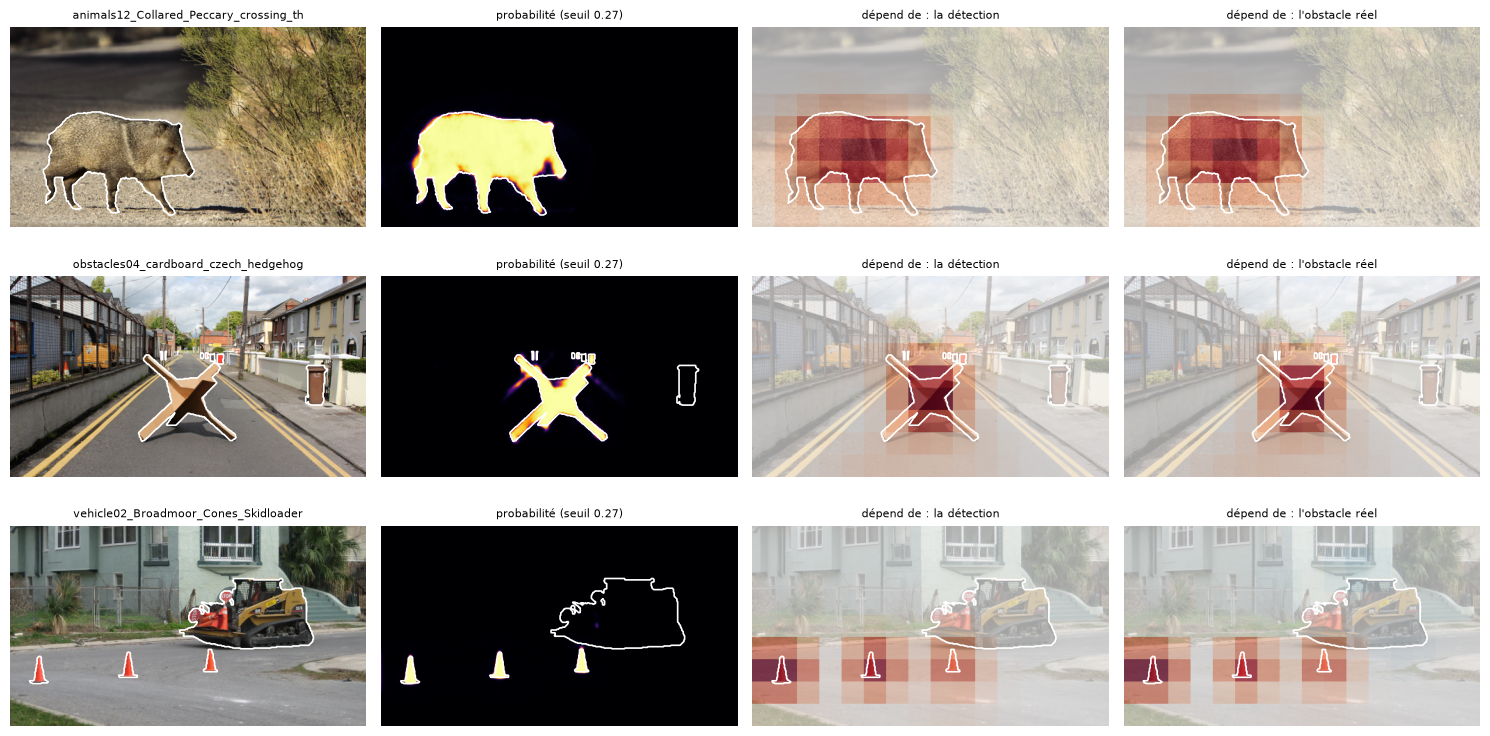

In [7]:
def plot_cases(names, fname, row_h=2.6):
    names = [n for n in names if n in RES]
    fig, axes = plt.subplots(len(names), 4, figsize=(15, row_h * len(names)), squeeze=False)
    for r, n in enumerate(names):
        d = RES[n]
        axes[r, 0].imshow(d["img"]); axes[r, 0].set_title(n[:38], fontsize=8)
        axes[r, 1].imshow(d["p0"], cmap="inferno", vmin=0, vmax=1); axes[r, 1].set_title(f"probabilité (seuil {THR:.2f})", fontsize=8)
        for c, key, title in [(2, "sens_pred", "dépend de : la détection"), (3, "sens_gt", "dépend de : l'obstacle réel")]:
            v = max(float(np.abs(d[key]).max()), 1e-6)
            axes[r, c].imshow(d["img"]); axes[r, c].imshow(d[key], cmap="RdBu_r", vmin=-v, vmax=v, alpha=0.65)
            axes[r, c].set_title(title, fontsize=8)
        for c in range(4):
            axes[r, c].contour(d["gt"].astype(float), levels=[0.5], colors="white", linewidths=1.2); axes[r, c].axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, fname), dpi=110, bbox_inches="tight"); plt.show()

plot_cases(CASES, "xai_occlusion_cas_etude.png")

## 4. Mesure sur les 12 images du test
Pour chaque image : **quelle part de la sensibilité positive tombe sur l'obstacle réel ?** Si cette part est bien supérieure à la surface de l'obstacle, le modèle s'appuie sur l'obstacle. Si elle lui est proche, il s'appuie surtout sur le contexte. Le **rapport** (part / surface) vaut 1 si le modèle regarde au hasard.

In [8]:
def share_inside(sens, mask):
    pos = np.clip(sens, 0, None); tot = pos.sum()
    return float(pos[mask].sum() / tot) if tot > 0 else float("nan")

rows = []
for n, d in RES.items():
    area = float(d["gt"].mean())
    share = share_inside(d["sens_pred"], d["gt"]) if d["pred0"].any() else float("nan")
    tp = int((d["pred0"] & d["gt"]).sum())
    rows.append({"Image": n, "Obstacle (% de l'image)": area * 100, "Rappel au seuil": tp / max(int(d["gt"].sum()), 1),
                 "Part de la sensibilité sur l'obstacle (%)": share * 100, "Rapport part / surface": share / area if area > 0 else float("nan")})
xai = pd.DataFrame(rows).sort_values("Rapport part / surface")
display(xai.round(2))
col_share, col_area = "Part de la sensibilité sur l'obstacle (%)", "Obstacle (% de l'image)"
print(f"Moyenne : {xai[col_share].mean():.0f} % de la sensibilité sur l'obstacle, qui occupe en moyenne {xai[col_area].mean():.0f} % de l'image")
xai.round(3).to_csv(os.path.join(OUT_DIR, "xai_occlusion_tableau.csv"), index=False, encoding="utf-8-sig")

,Image,Obstacle (% de l'image),Rappel au seuil,Part de la sensibilité sur l'obstacle (%),Rapport part / surface
11,vehicle02_Broadmoor_Cones_Skidloader,9.97,0.08,9.48,0.95
10,obstacles11_boulder5,22.70,0.91,65.78,2.90
2,animals14_Dekemhare_Road,9.95,0.94,42.63,4.29
0,animals12_Collared_Peccary_crossing_the_road,13.03,0.98,60.23,4.62
5,animals30,6.64,0.93,32.14,4.84
3,animals19_Porte_de_Roubaix,9.43,0.79,50.60,5.37
8,obstacles04_cardboard_czech_hedgehog,4.77,0.76,28.85,6.05
4,animals26_Unnamed_Road_Kazakhstan,4.92,0.92,36.78,7.48
9,obstacles09_boulder3,5.14,0.92,46.30,9.01
7,cones07,1.37,0.84,14.37,10.52


Moyenne : 36 % de la sensibilité sur l'obstacle, qui occupe en moyenne 8 % de l'image


## 5. Toutes les images du test (pour l'annexe)

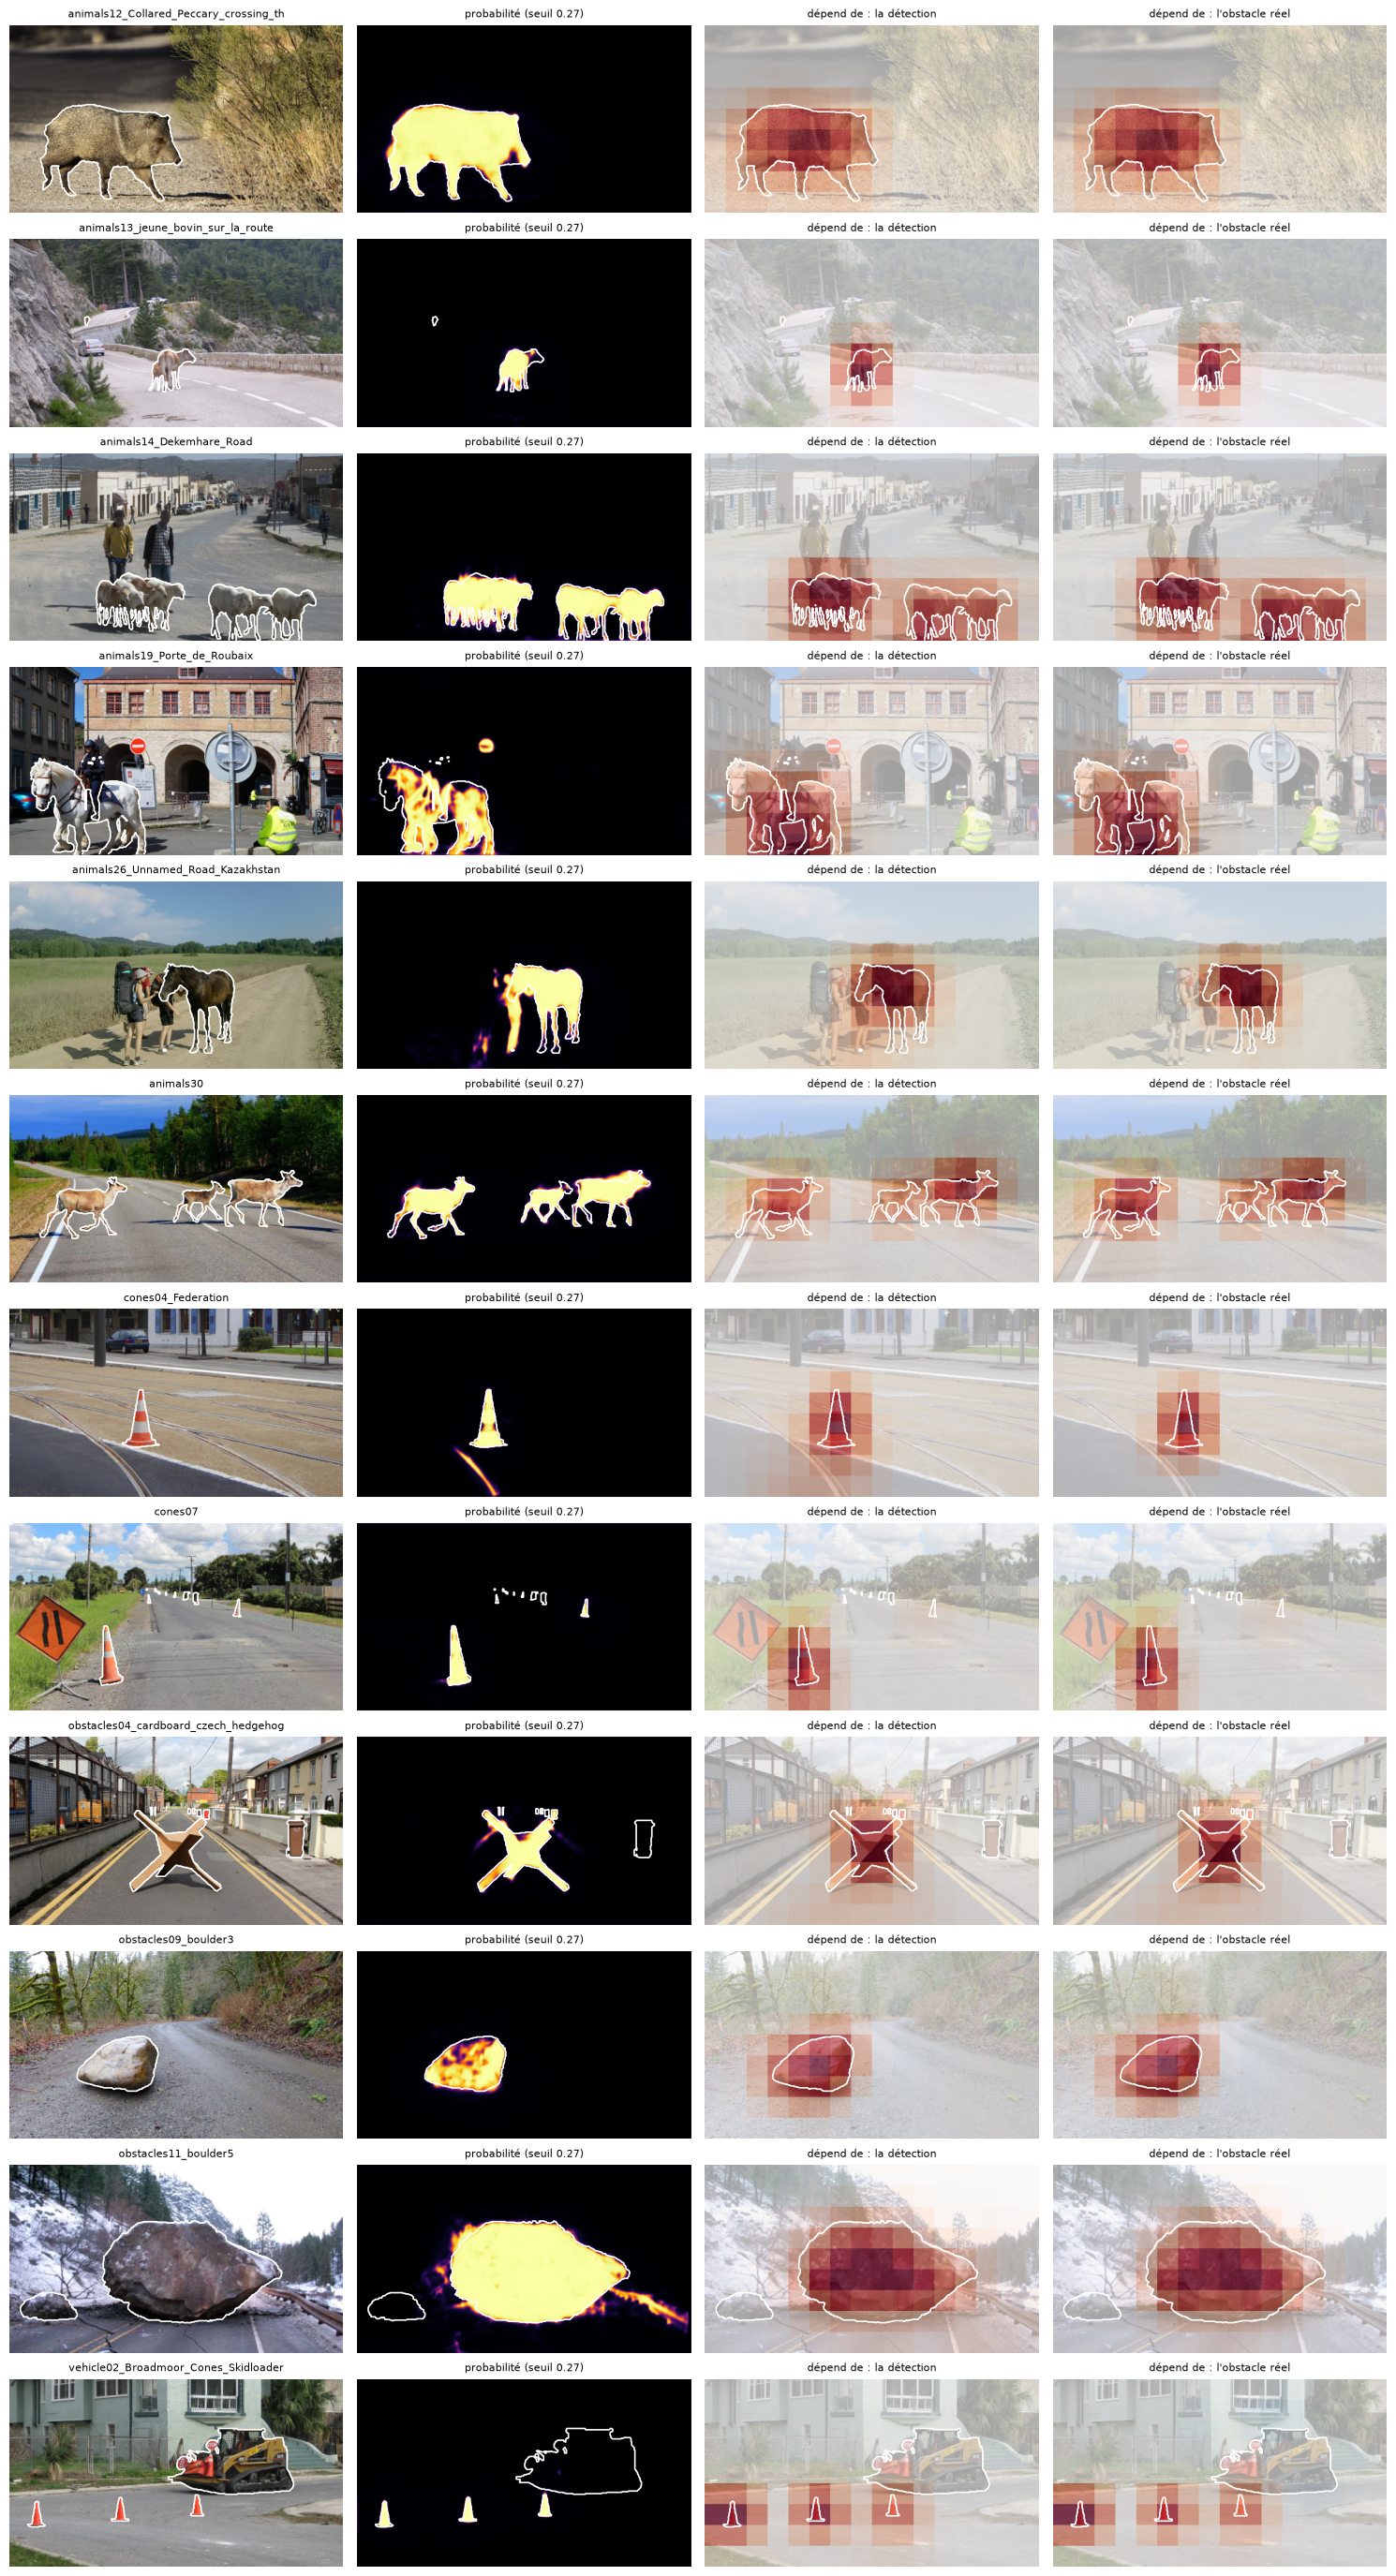

Fichiers : ['xai_occlusion_cas_etude.png', 'xai_occlusion_tableau.csv', 'xai_occlusion_toutes_images.png']


In [9]:
plot_cases(test_names, "xai_occlusion_toutes_images.png", row_h=2.3)
print("Fichiers :", sorted(os.listdir(OUT_DIR)))

## 6. Lecture à compléter avec vos résultats

1. **Cas bien détecté** (`animals12`) : la zone rouge recouvre-t-elle l'animal ? Si oui, le modèle s'appuie bien sur l'obstacle.
2. **Cas raté** (`vehicle02`) : où est la sensibilité du score « détection » ? Si elle est sur les cônes et pas sur l'engin, le modèle a appris que les cônes sont des anomalies et pas que les engins de chantier, ce qui explique l'obstacle manqué.
3. **Rapport part / surface** : la valeur moyenne dit si le modèle regarde l'obstacle (nettement supérieur à 1) ou le décor (proche de 1). Cherchez les images en dessous de 1.
4. **Limites à écrire :** le test d'occlusion montre une dépendance, pas une causalité ; un carré de 64 px est grossier pour les petits objets (cônes) ; le carré gris est lui-même hors distribution et peut créer de fausses réponses ; 12 images ne permettent pas de généraliser.
5. **Piste :** Grad-CAM donnerait une carte plus fine, au prix d'un accès aux couches internes du réseau.